# Прогноз продаж небольшой пекарни

В ноутбуке проверяется, помогает ли машинное обучение предсказывать ежедневные продажи восьми товаров. Работа включает подготовку данных, сравнение методов и разбор ошибок. Основные функции находятся в `src/bakery_forecast` и используются также командами проекта.

## 1. Бизнес-задача и гипотеза

Управляющий выбирает объём выпечки на следующий день. Избыток приводит к остаткам, нехватка — к потерянным продажам. Проверяем, даст ли модель меньшую ошибку, чем прогноз по продажам неделю назад и среднему четырёх предыдущих одинаковых дней недели. Целевая переменная — количество проданного товара за день с учётом корректировок.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Откройте ноутбук из папки проекта'
sys.path.insert(0, str(ROOT / 'src'))
from bakery_forecast.data import download_data, read_transactions, daily_panel  # noqa: E402
from bakery_forecast.features import make_features  # noqa: E402
from bakery_forecast.experiment import run_experiment, predict_next_day  # noqa: E402

## 2. Получение данных

Использован набор Matthieu Gimbert, French Bakery Daily Sales. Автор описывает его как кассовые продажи французской пекарни. Загрузчик проверяет версию файла по SHA-256. Условия использования приведены в `DATA_LICENSE.md`. [Источник данных](https://www.kaggle.com/datasets/matthieugimbert/french-bakery-daily-sales).

In [2]:
raw_path = download_data(ROOT / 'data/raw/Bakery sales.csv')
transactions, audit = read_transactions(raw_path)
display(pd.DataFrame([{k: audit[k] for k in ['raw_rows', 'observed_dates', 'products_in_source', 'first_date', 'last_date', 'negative_quantity_rows_retained', 'repeated_content_rows_retained']}]).T.rename(columns={0: 'Значение'}))
print('Дат без записей:', len(audit['dates_without_any_transactions']))
print('SHA-256:', audit['sha256'])

,Значение
raw_rows,234005
observed_dates,600
products_in_source,149
first_date,2021-01-02
last_date,2022-09-30
negative_quantity_rows_retained,1295
repeated_content_rows_retained,1210


Дат без записей: 37
SHA-256: af5eede55b6eb2efb6bebb0e6dd1a51568c7eb73554d2f8ad2563081025681b2


## 3. Подготовка данных

Количество суммируется с учётом корректировок. Совпадающие строки сохраняются, поскольку уникального идентификатора позиции чека нет. Даты без записей остаются неизвестными. Если другие товары в этот день продавались, отсутствие выбранного товара принимается за нулевые продажи. Число таких случаев выводится ниже.

In [3]:
panel = daily_panel(transactions)
display(panel.groupby('product').agg(known_days=('y', 'count'), units=('y', 'sum'), average=('y', 'mean')).round(2))
print('Неизвестных пар товар–день:', panel.y.isna().sum())
print('Предположений о нулевых продажах:', panel.product_absence_assumed_zero.sum())

,known_days,units,average
product,,,
BAGUETTE,600,22053.0,36.76
BANETTE,600,22732.0,37.89
BOULE 400G,600,4824.0,8.04
CAMPAGNE,600,4356.0,7.26
CEREAL BAGUETTE,600,7427.0,12.38
CROISSANT,600,29654.0,49.42
PAIN AU CHOCOLAT,600,25236.0,42.06
TRADITIONAL BAGUETTE,600,117463.0,195.77


Неизвестных пар товар–день: 296
Предположений о нулевых продажах: 16


## 4. Признаки

Модель получает календарь, название товара, лаги и средние по прошлой истории. Лаг 7 означает продажи семь дней назад. Для даты t используются значения, известные до t. Следующая ячейка проверяет это условие, заменяя текущие и будущие продажи большими числами.

In [4]:
from bakery_forecast.config import FEATURES
features = make_features(panel)
display(pd.DataFrame({'Признак': FEATURES}))
# Изменение будущих целей не должно менять текущие признаки.
changed = panel.copy()
cutoff = pd.Timestamp('2022-06-01')
changed.loc[changed.date >= cutoff, 'y'] = 100000
changed_features = make_features(changed)
pd.testing.assert_frame_equal(features.loc[features.date <= cutoff, FEATURES], changed_features.loc[changed_features.date <= cutoff, FEATURES])
print('Проверка: текущие и будущие цели не влияют на признаки текущего дня.')

,Признак
0,product
1,dow
2,month
3,weekend
4,annual_sin
5,annual_cos
6,trend
7,lag_1
8,lag_7
9,lag_14


Проверка: текущие и будущие цели не влияют на признаки текущего дня.


## 5. Обучение и проверка по времени

Модель выбирается по WAPE на июне и июле 2022 года. Август и сентябрь отложены для итогового теста. Каждый прогноз относится к одному дню. Продажи прошедших дней доступны для расчёта следующих прогнозов, веса модели в течение теста фиксированы. Следующая ячейка выполняет эксперимент и сохраняет отчёты.

In [5]:
summary = run_experiment(raw_path, ROOT)
print('Модель, выбранная на валидации:', summary['selected_model'])

Validation 2022-06-01 .. 2022-07-01


Validation 2022-07-01 .. 2022-08-01


Selected on validation: hgb_absolute. Evaluating untouched test period.


Модель, выбранная на валидации: hgb_absolute


## 6. Результаты

MAE показывает средний промах в штуках на один товар за день. WAPE показывает отношение суммы абсолютных ошибок к общему объёму продаж. Сначала сравниваются общие результаты, затем отдельные товары и месяцы.

,validation_WAPE_pct,test_WAPE_pct,test_MAE_units
model,,,
lag_7,34.85,28.07,18.78
weekday_mean_4,33.73,42.08,28.15
hgb_absolute,21.40,18.28,12.23
hgb_poisson,22.17,17.00,11.37
blend_absolute,26.05,28.40,19.00


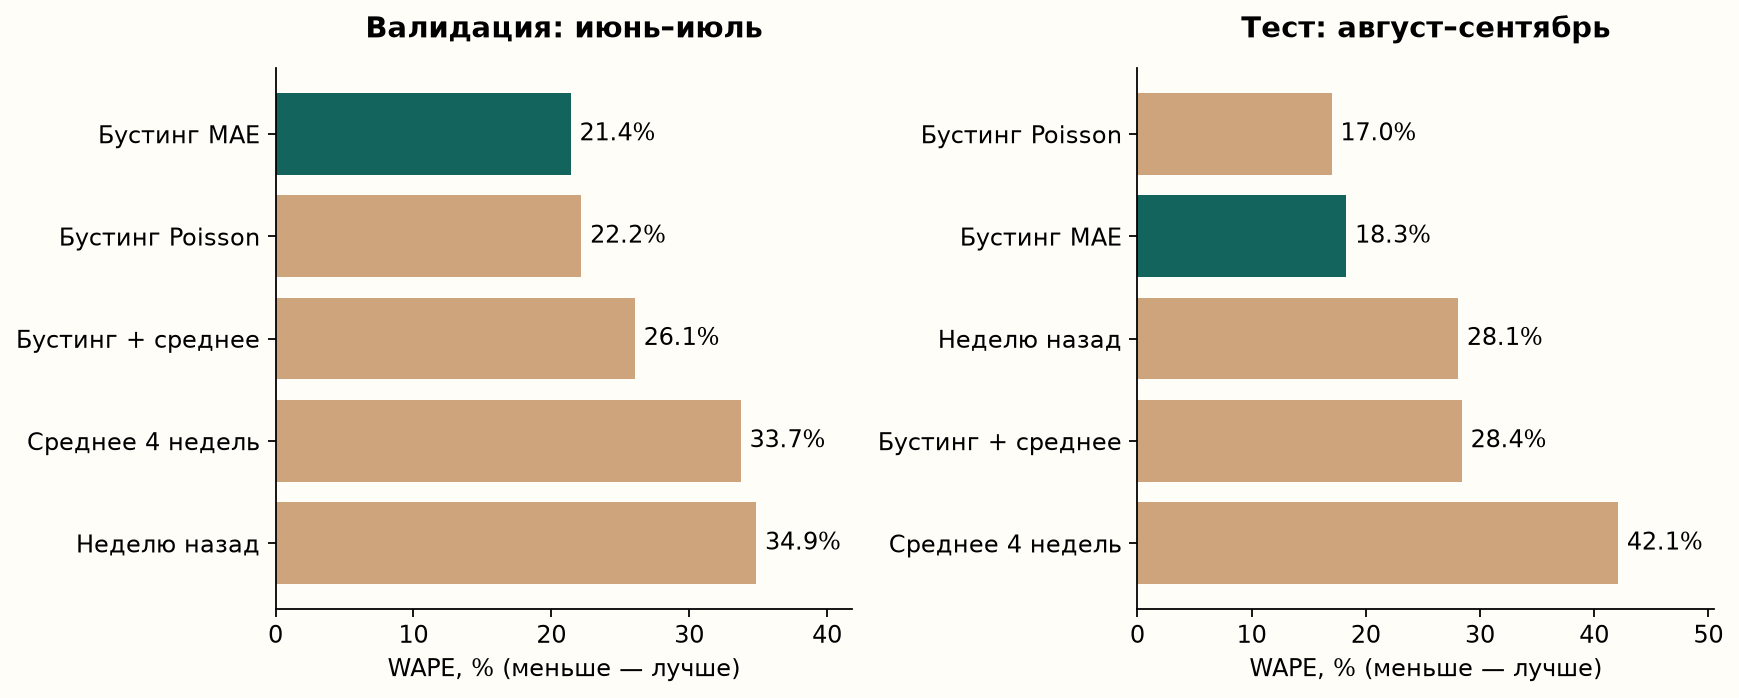

In [6]:
validation = pd.DataFrame(summary['validation_metrics']).set_index('model')
test = pd.DataFrame(summary['test_metrics']).set_index('model')
comparison = validation[['wape_pct']].rename(columns={'wape_pct': 'validation_WAPE_pct'}).join(test[['wape_pct', 'mae']].rename(columns={'wape_pct':'test_WAPE_pct', 'mae':'test_MAE_units'}))
display(comparison.round(2))
display(Image(filename=str(ROOT / 'reports/figures/model_comparison.png')))

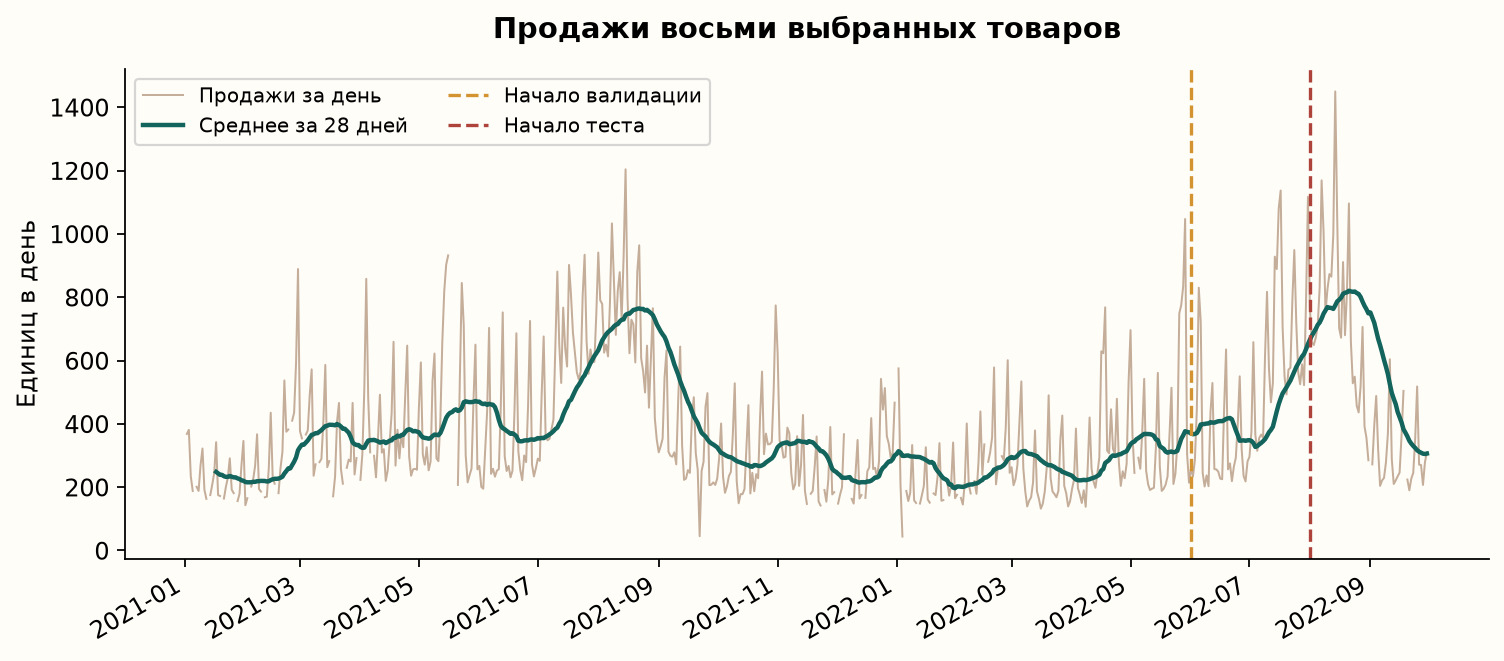

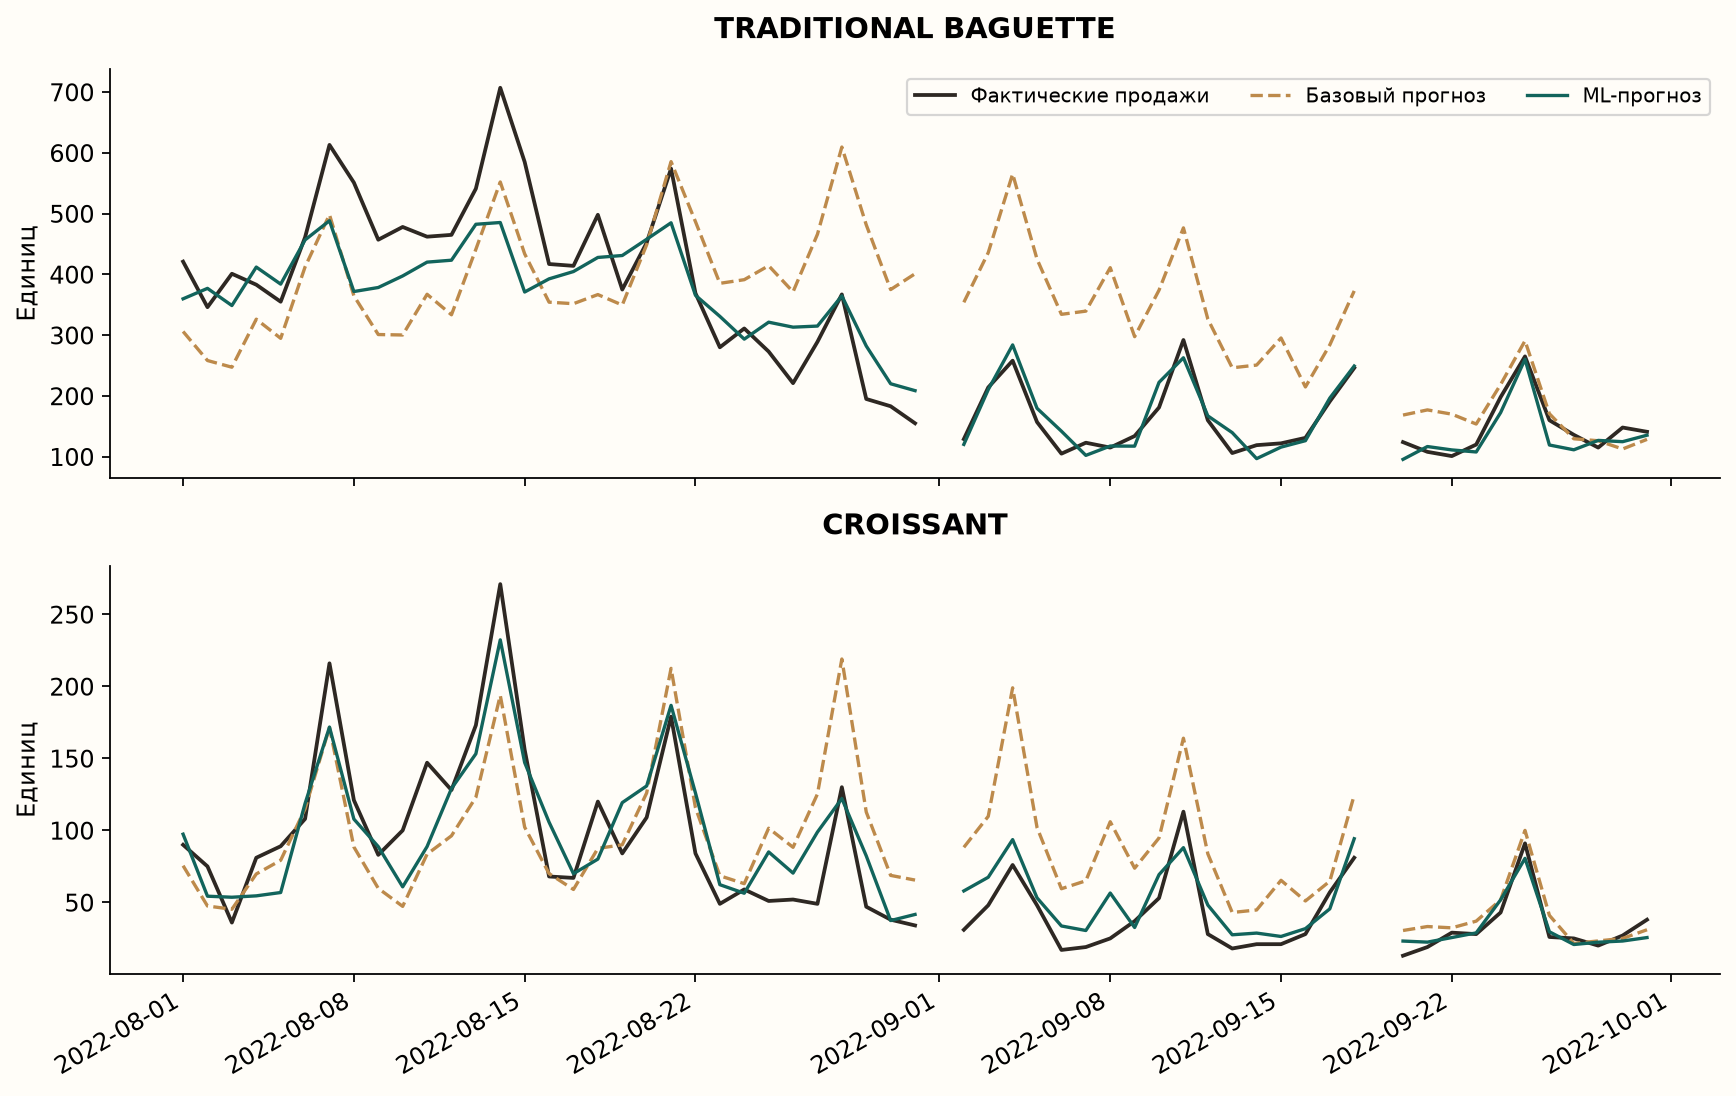

month,2022-08,2022-09
model,,
blend_absolute,22.71,43.74
hgb_absolute,17.91,19.27
hgb_poisson,16.52,18.28
lag_7,27.98,28.32
weekday_mean_4,29.70,75.50


In [7]:
display(Image(filename=str(ROOT / 'reports/figures/sales_history.png')))
display(Image(filename=str(ROOT / 'reports/figures/test_forecast.png')))
monthly = pd.read_csv(ROOT / 'reports/metrics_by_month.csv')
display(monthly.pivot(index='model', columns='month', values='wape_pct').round(2))

На валидации выбран бустинг MAE. На тесте Poisson получил меньший WAPE. Его можно рассмотреть в следующем эксперименте со свежим периодом оценки. Полная таблица показывает результаты всех пяти кандидатов.

In [8]:
ci = summary['ml_minus_baseline_wape_ci']
print('95%-интервал разности WAPE (ML минус выбранный baseline), п.п.:', round(ci['low_pp'],2), round(ci['high_pp'],2))
print('Блочный bootstrap:', ci['repeats'], 'повторов, блок', ci['block_days'], 'дней')
per_product = pd.read_csv(ROOT / 'reports/metrics_by_product.csv')
display(per_product[per_product.model == summary['selected_model']][['product','wape_pct','mae']].round(2))

95%-интервал разности WAPE (ML минус выбранный baseline), п.п.: -53.51 -9.36
Блочный bootstrap: 2000 повторов, блок 7 дней


,product,wape_pct,mae
2,BAGUETTE,19.07,7.62
7,BANETTE,18.96,8.87
12,BOULE 400G,28.52,2.76
17,CAMPAGNE,27.54,2.53
22,CEREAL BAGUETTE,23.60,2.84
27,CROISSANT,24.20,17.12
32,PAIN AU CHOCOLAT,26.03,15.28
37,TRADITIONAL BAGUETTE,14.16,40.81


### 6.1. Ошибки по товарам

Сравним общий результат с отдельными изделиями. Положительная знаковая ошибка означает завышение, отрицательная — занижение прогноза.

,model_WAPE_pct,model_MAE_units,model_bias_units,lag7_WAPE_pct
product,,,,
BAGUETTE,19.07,7.62,3.52,24.99
BANETTE,18.96,8.87,1.18,26.40
BOULE 400G,28.52,2.76,0.80,40.22
CAMPAGNE,27.54,2.53,0.79,34.97
CEREAL BAGUETTE,23.60,2.84,1.39,25.65
CROISSANT,24.20,17.12,2.62,36.14
PAIN AU CHOCOLAT,26.03,15.28,1.80,35.47
TRADITIONAL BAGUETTE,14.16,40.81,-15.21,24.75


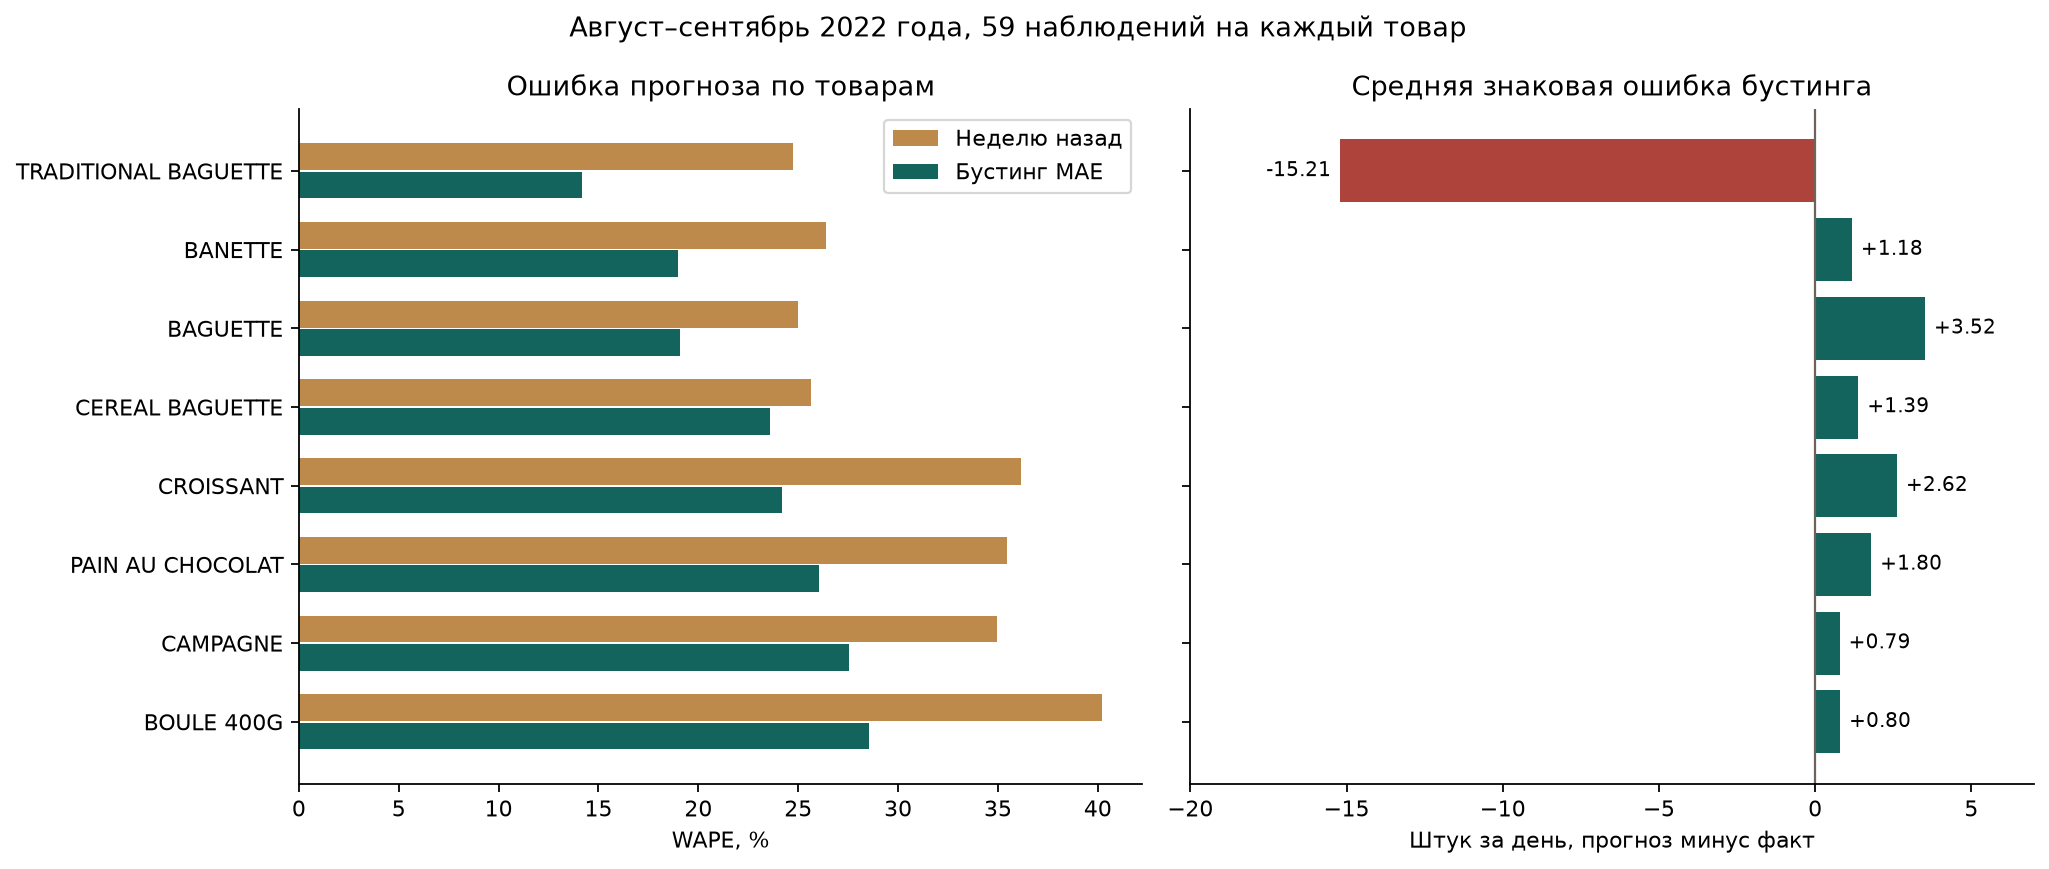

In [ ]:
import matplotlib.pyplot as plt

product_scores = pd.read_csv(ROOT / 'reports/metrics_by_product.csv')
selected_model = summary['selected_model']
selected_scores = product_scores[product_scores.model.eq(selected_model)].set_index('product')
week_scores = product_scores[product_scores.model.eq('lag_7')].set_index('product')
product_comparison = selected_scores[['wape_pct', 'mae', 'bias_units']].rename(
    columns={'wape_pct': 'model_WAPE_pct', 'mae': 'model_MAE_units', 'bias_units': 'model_bias_units'}
).join(week_scores[['wape_pct']].rename(columns={'wape_pct': 'lag7_WAPE_pct'}))
display(product_comparison.round(2))

plot_table = product_comparison.sort_values('model_WAPE_pct')
positions = list(range(len(plot_table)))
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
    axes[0].barh([y - 0.18 for y in positions], plot_table.lag7_WAPE_pct,
                 height=0.34, color='#bd8a4b', label='Неделю назад')
    axes[0].barh([y + 0.18 for y in positions], plot_table.model_WAPE_pct,
                 height=0.34, color='#12645c', label='Бустинг MAE')
    axes[0].set_yticks(positions, labels=plot_table.index)
    axes[0].invert_yaxis()
    axes[0].set(title='Ошибка прогноза по товарам', xlabel='WAPE, %')
    axes[0].legend(loc='upper right')

    colors = ['#ad433b' if value < 0 else '#12645c' for value in plot_table.model_bias_units]
    bars = axes[1].barh(positions, plot_table.model_bias_units, color=colors)
    axes[1].bar_label(bars, fmt='%+.2f', padding=4, fontsize=9)
    axes[1].axvline(0, color='#6f645b', linewidth=1)
    axes[1].set(title='Средняя знаковая ошибка бустинга',
                xlabel='Штук за день, прогноз минус факт', xlim=(-20, 7))
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Август–сентябрь 2022 года, 59 наблюдений на каждый товар', fontsize=12)
    fig.tight_layout()
    figure_path = ROOT / 'reports/figures/errors_by_product.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=160, bbox_inches='tight', facecolor='white')
    plt.close(fig)
display(Image(filename=str(figure_path)))

У TRADITIONAL BAGUETTE WAPE равен 14,16%, а средняя знаковая ошибка составляет −15,21 штуки в день. У BOULE 400G WAPE выше, 28,52%, при MAE 2,76 штуки. Высокие продажи традиционного багета объясняют сочетание меньшей процентной ошибки и большей ошибки в штуках.

Бустинг имеет меньший WAPE, чем правило «неделю назад», по всем восьми товарам. У CEREAL BAGUETTE относительное улучшение составляет около 8,01%. Этот товар требует отдельного внимания при проверке на новой истории.

## 7. Сценарная экономика

Стоимость ошибки рассчитывается по формуле `c × max(Q − D, 0) + (p − c) × max(D − Q, 0)`. Здесь Q — выпуск, D — спрос, p — цена, c — себестоимость. В сценариях по датасету продажи приняты за спрос. Цена рассчитана по обучающей истории, себестоимость задаётся как 30%, 50% или 70% цены. Коэффициент выпуска выбирается на валидации. Предполагается полное списание излишка в конце дня.

,model,cost_ratio,multiplier,loss_eur,surplus_units,shortage_units
0,lag_7,0.3,1.2,4692.83,10794.0,1104.0
1,weekday_mean_4,0.3,1.3,7101.42,18304.0,823.0
2,hgb_absolute,0.3,1.2,3220.70,7027.0,933.0
3,hgb_poisson,0.3,1.2,2895.90,6391.0,814.0
4,blend_absolute,0.3,1.2,4658.38,10906.0,1014.0
5,lag_7,0.5,1.0,5195.98,5836.0,3028.0
6,weekday_mean_4,0.5,1.1,8655.00,12345.0,2417.0
7,hgb_absolute,0.5,1.0,3377.65,2791.0,2978.0
8,hgb_poisson,0.5,1.0,3140.85,2379.0,2991.0
9,blend_absolute,0.5,1.1,5893.15,8253.0,1816.0


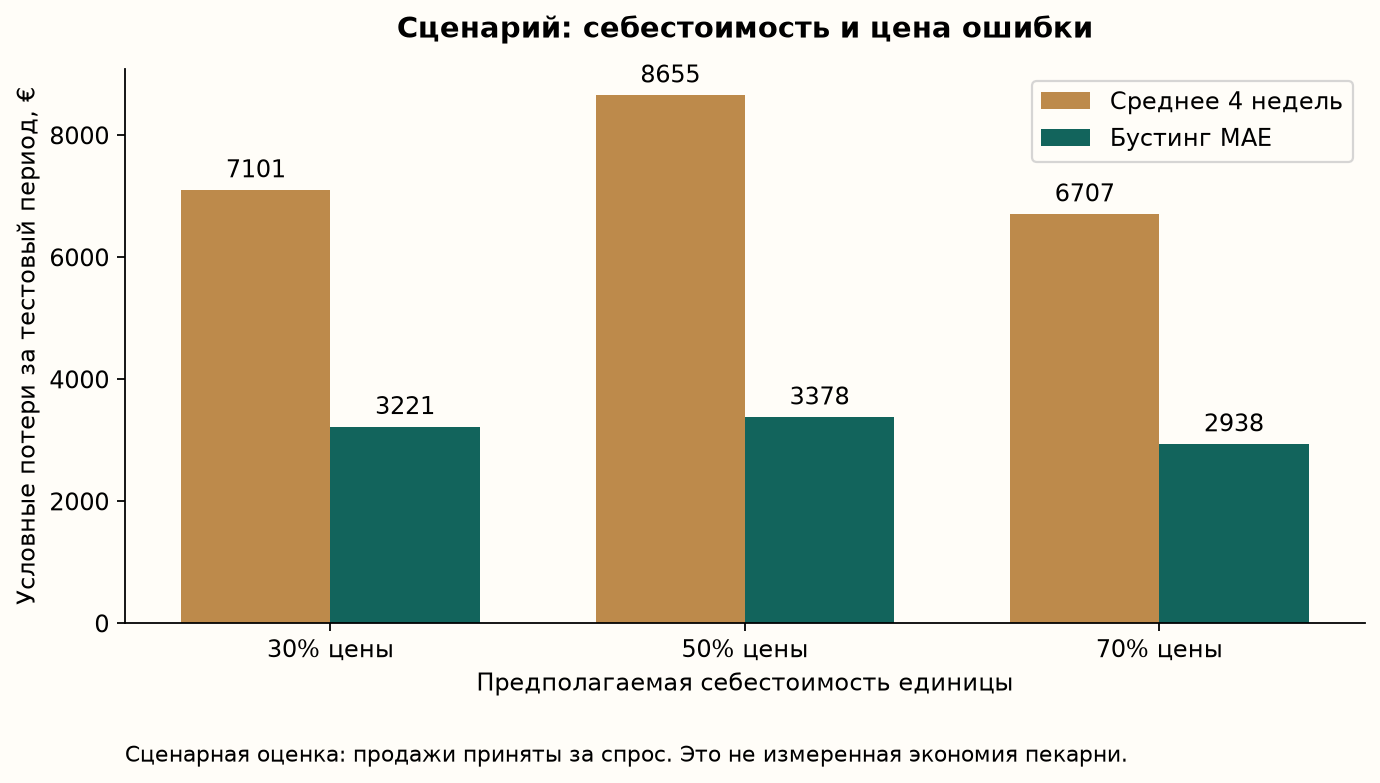

In [9]:
economics = pd.read_csv(ROOT / 'reports/economic_scenarios.csv')
display(economics[['model','cost_ratio','multiplier','loss_eur','surplus_units','shortage_units']].round(2))
display(Image(filename=str(ROOT / 'reports/figures/economic_scenarios.png')))

### 7.1. Учебный пример стоимости ошибки

Зададим цену 2 евро, себестоимость 0,80 евро и спрос 100 штук. Рассчитаем потери при выпуске 80, 100 и 120 штук с помощью той же функции, которая используется в эксперименте.

In [ ]:
from bakery_forecast.metrics import inventory_loss

example_price = 2.0
example_cost = 0.8
example_demand = 100
example_rows = []
for planned_units in [80, 100, 120]:
    result = inventory_loss(
        actual=[example_demand], forecast=[planned_units], price=[example_price],
        cost_ratio=example_cost / example_price,
    )
    example_rows.append({'Выпуск, шт.': planned_units,
                         'Излишек, шт.': result['surplus_units'],
                         'Нехватка, шт.': result['shortage_units'],
                         'Потери, евро': result['loss_eur']})
display(pd.DataFrame(example_rows).round(2))

,"Выпуск, шт.","Излишек, шт.","Нехватка, шт.","Потери, евро"
0,80,0.0,20.0,24.0
1,100,0.0,0.0,0.0
2,120,20.0,0.0,16.0


При недовыпуске 20 изделий упущенная маржа равна 24 евро. При излишке 20 изделий затраты составляют 16 евро. В этом примере ошибка одинакового размера имеет разную стоимость в зависимости от направления.

## 8. Пример использования

После оценки выбранная модель отдельно обучается на всей доступной истории. Ниже рассчитывается прогноз на 1 октября 2022 года, следующий день после последней записи. Фактические продажи за эту дату в наборе отсутствуют. Для плана производства управляющему также нужны остатки и ограничения выпуска.

In [10]:
forecast = predict_next_day(raw_path, ROOT / 'models/forecast.joblib')
display(forecast)

,date,product,forecast_units,rounded_units,model
5096,2022-10-01,BAGUETTE,36.00,36,hgb_absolute
5097,2022-10-01,BANETTE,35.02,35,hgb_absolute
5098,2022-10-01,BOULE 400G,9.17,9,hgb_absolute
5099,2022-10-01,CAMPAGNE,9.42,9,hgb_absolute
5100,2022-10-01,CEREAL BAGUETTE,12.36,12,hgb_absolute
5101,2022-10-01,CROISSANT,48.00,48,hgb_absolute
5102,2022-10-01,PAIN AU CHOCOLAT,40.68,41,hgb_absolute
5103,2022-10-01,TRADITIONAL BAGUETTE,201.36,201,hgb_absolute


## 9. Выводы

На исходном тесте выбранный бустинг MAE получил WAPE 18,28% и MAE 12,23 штуки. Разбор по товарам выявил занижение прогноза традиционного багета. Это показывает необходимость проверять направление ошибки для каждого изделия.

Следующий шаг — оценка на свежей истории пекарни с данными о выпуске, остатках и списаниях. Подробные выводы и дополнительная проверка на 11 месячных окнах приведены в `docs/coursework.md` и `reports/research/results.md`.

In [11]:
display(Markdown((ROOT / 'reports/results.md').read_text().split('## Сценарная экономика')[0].replace('![Сравнение моделей](figures/model_comparison.png)', '').replace('![Прогнозы на тесте](figures/test_forecast.png)', '')))

# Результаты воспроизводимого эксперимента

Источник: French Bakery Daily Sales. SHA-256: `af5eede55b6eb2efb6bebb0e6dd1a51568c7eb73554d2f8ad2563081025681b2`.

Исходных строк: **234,005**. Дней с записями: **600**. Период: 2021-01-02 — 2022-09-30. В эксперименте восемь товаров.

## Схема проверки

Две расширяющиеся выборки: обучение до 01.06.2022, проверка на июне; обучение до 01.07.2022, проверка на июле. Основную модель выбираем по суммарному WAPE двух проверок. Затем переобучаем на данных до 01.08.2022 и оцениваем август–сентябрь.

Модель, выбранная до теста: **hgb_absolute**. Тест: **59** дней с записями, **472** пар «день–товар».

Прогноз формируется каждый вечер на следующий день. Фактические продажи прошедших дней теста доступны для лагов, веса модели в течение теста не меняются. Это серия однодневных прогнозов, а не прогноз сразу на два месяца.

## Качество

| Модель | WAPE, валидация | WAPE, тест | MAE, тест, шт. |
|---|---:|---:|---:|
| Неделю назад (`lag_7`) | 34.85% | 28.07% | 18.78 |
| Среднее 4 недель (`weekday_mean_4`) | 33.73% | 42.08% | 28.15 |
| Бустинг MAE (`hgb_absolute`) | 21.40% | 18.28% | 12.23 |
| Бустинг Poisson (`hgb_poisson`) | 22.17% | 17.00% | 11.37 |
| Бустинг + среднее (`blend_absolute`) | 26.05% | 28.40% | 19.00 |

Лучшая ML-модель по валидации: `hgb_absolute`. Снижение WAPE относительно выбранного на валидации базового метода `weekday_mean_4` на тесте: **56.56%**. Относительно «неделю назад»: **34.88%**.

Все кандидаты показаны для прозрачности. Выбирать другую основную модель по результатам этого же теста нельзя: для нового выбора понадобится новый период проверки.

Приблизительный 95%-интервал разности WAPE (ML минус выбранный baseline): **[-53.51; -9.36] п.п.** Парный блочный bootstrap: 2 000 повторов, блок семь календарных дней. Интервал относится к данному короткому периоду и не доказывает переносимость на другие пекарни.





